In [4]:
# ==========================================
# 1. IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pickle
import os

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# ==========================================
# 2. LOAD THE DATASET
# ==========================================

df = pd.read_csv("C:/Users/adish/Downloads/diabetes (2).csv")

print("Dataset loaded successfully!")
print("\nFirst five rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!

First five rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset shape:
(768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [6]:
# ==========================================
# 3. EXPLORATORY DATA ANALYSIS
# ==========================================

print("Dataset Information:")
df.info()

print("\nSummary Statistics:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTarget Variable Distribution:")
print(df["Outcome"].value_counts())

print("\nTarget Variable Percentages:")
print(df["Outcome"].value_counts(normalize=True) * 100)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Summary Statistics:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536

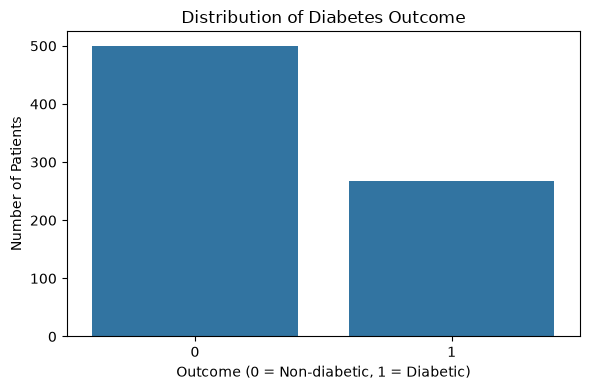

In [7]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Outcome")

plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 = Non-diabetic, 1 = Diabetic)")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

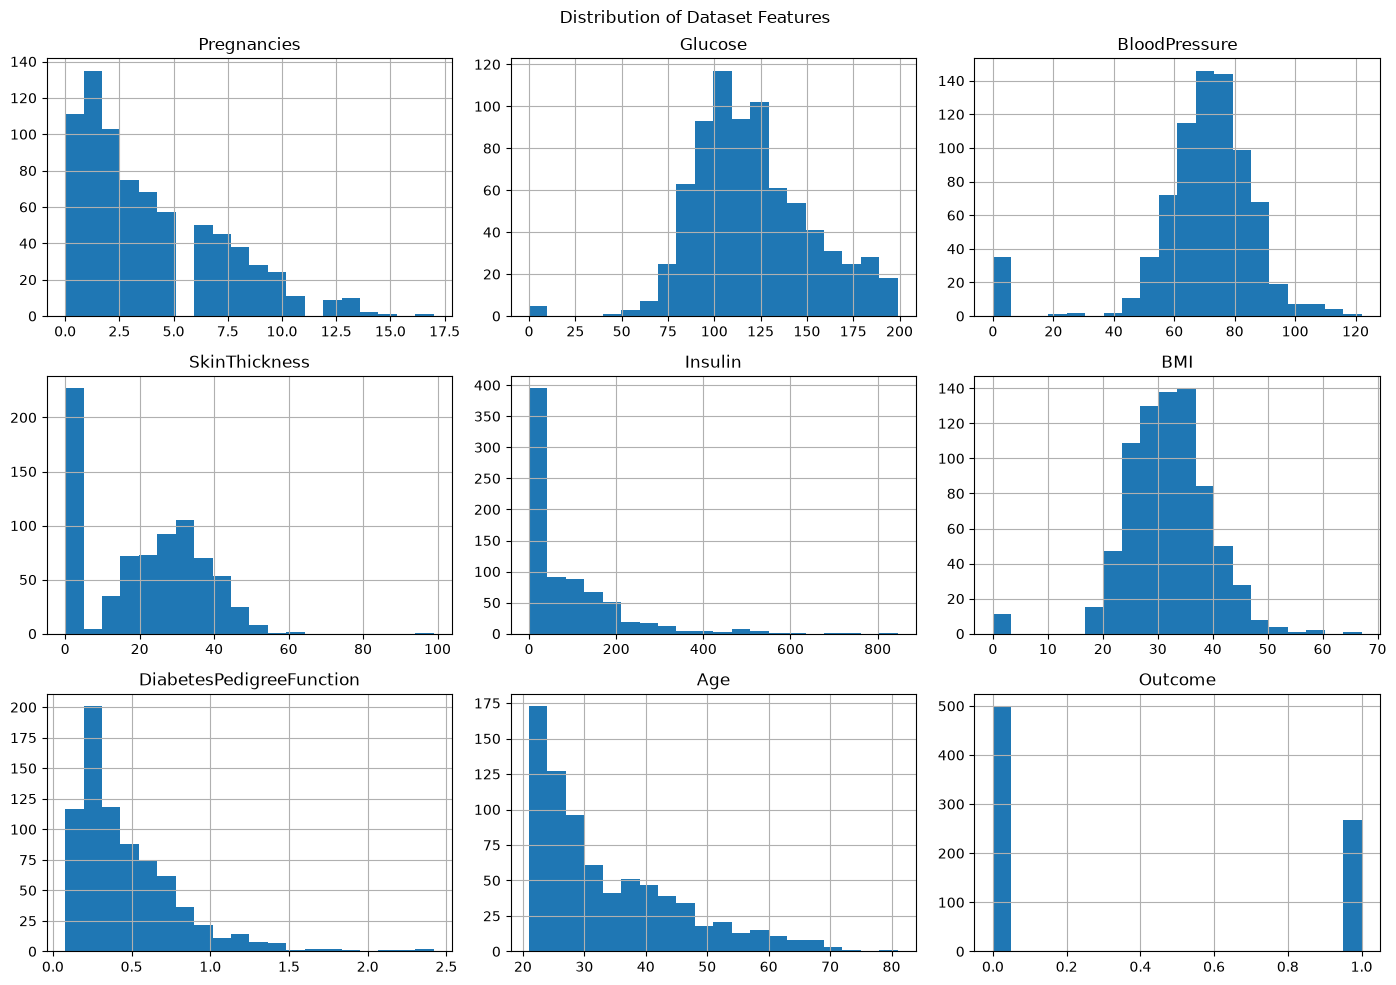

In [8]:
df.hist(figsize=(14, 10), bins=20)

plt.suptitle("Distribution of Dataset Features")
plt.tight_layout()
plt.show()

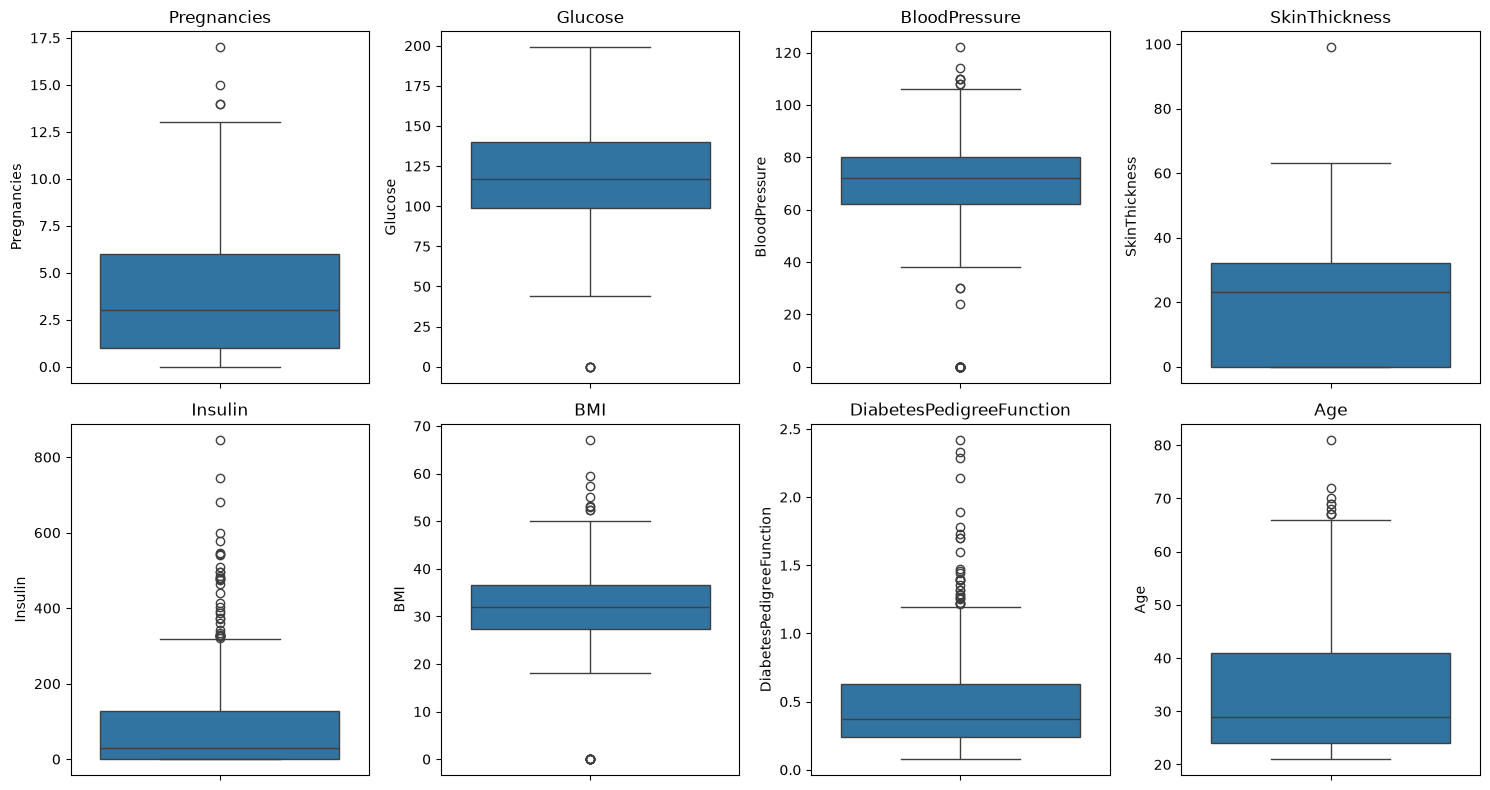

In [9]:
numeric_features = df.drop(columns=["Outcome"]).columns

plt.figure(figsize=(15, 8))

for i, column in enumerate(numeric_features, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

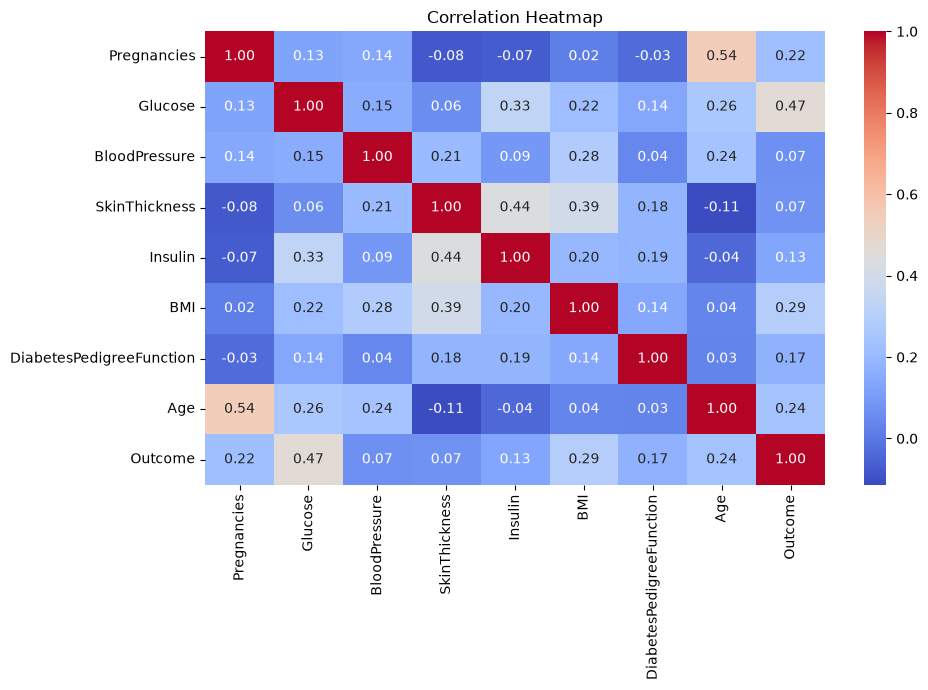

In [10]:
plt.figure(figsize=(10, 7))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

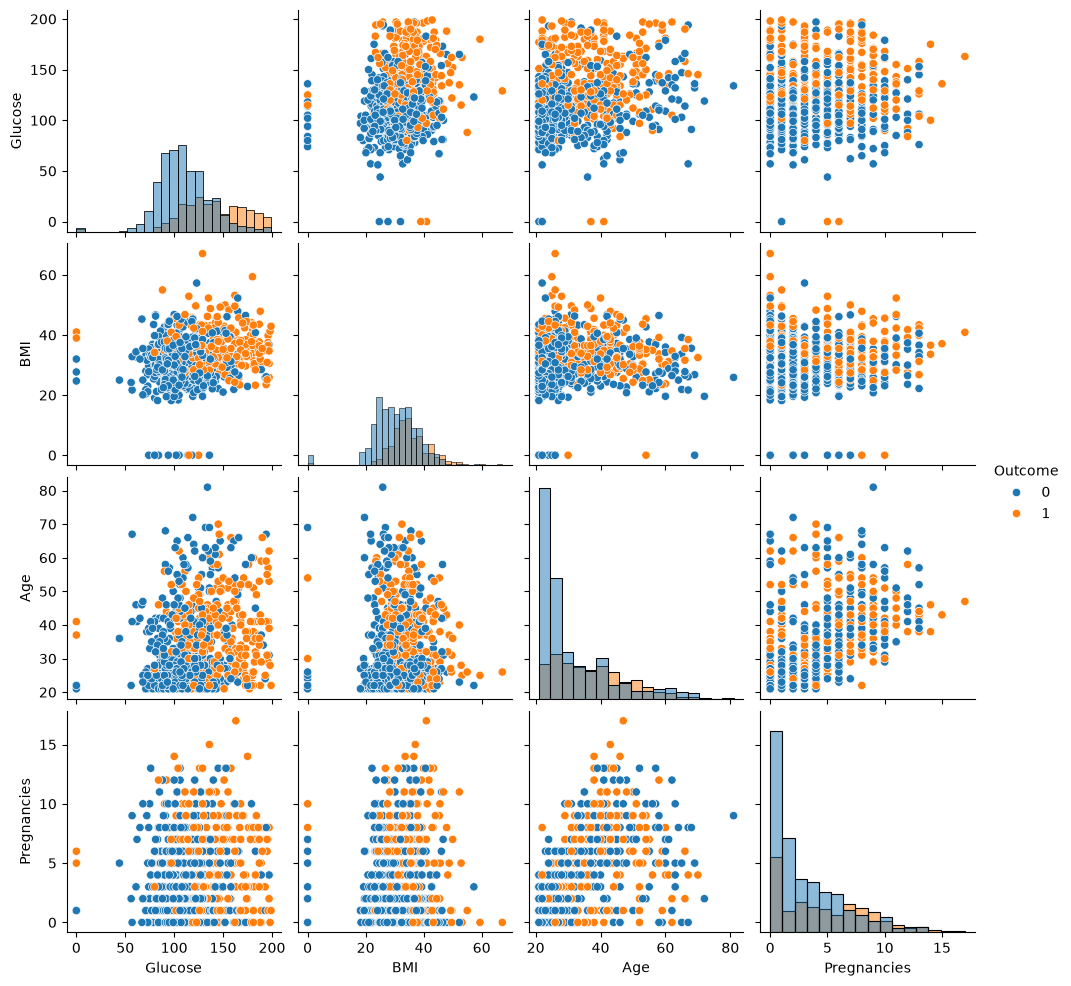

In [11]:
selected_features = [
    "Glucose",
    "BMI",
    "Age",
    "Pregnancies",
    "Outcome"
]

sns.pairplot(
    df[selected_features],
    hue="Outcome",
    diag_kind="hist"
)

plt.show()

#### EDA observations

The dataset contains 768 records and nine columns. Eight columns represent patient measurements, and the Outcome column indicates diabetes status.

The features include pregnancies, glucose, blood pressure, skin thickness, insulin, BMI, diabetes pedigree function, and age.

The initial missing-value check identifies no explicitly recorded missing values. However, zero values in certain medical measurements may represent missing or unrecorded measurements rather than genuine observations.

The histograms show the distributions of individual features, while box plots help identify potential outliers. The correlation heatmap shows relationships between numerical variables. These visualisations help identify patterns that may be useful when predicting diabetes.

In [12]:
# ==========================================
# 5. DATA PREPROCESSING
# ==========================================

# Create a separate copy for preprocessing
data = df.copy()

# Identify features where zero may represent a missing measurement
zero_missing_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("Zero values before preprocessing:")

for column in zero_missing_columns:
    print(column, ":", (data[column] == 0).sum())

# Convert zero values to NaN in the specified features
data[zero_missing_columns] = data[zero_missing_columns].replace(0, np.nan)

print("\nMissing values after replacing selected zeros:")
print(data.isnull().sum())

Zero values before preprocessing:
Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11

Missing values after replacing selected zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [13]:
# ==========================================
# 6. SEPARATE FEATURES AND TARGET
# ==========================================

X = data.drop(columns=["Outcome"])
y = data["Outcome"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Outcome")

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Target:
Outcome

Feature shape: (768, 8)
Target shape: (768,)


In [14]:
# ==========================================
# 7. TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (576, 8)
Testing features: (192, 8)
Training target: (576,)
Testing target: (192,)


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [16]:
# ==========================================
# 8. BUILD AND TRAIN THE MODEL
# ==========================================

log_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

log_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [17]:
# ==========================================
# 9. MAKE PREDICTIONS
# ==========================================

y_pred = log_model.predict(X_test)

y_probability = log_model.predict_proba(X_test)[:, 1]

print("First 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])

print("\nFirst 10 predicted probabilities:")
print(y_probability[:10])

First 10 actual values:
[1 0 0 1 1 0 0 0 0 0]

First 10 predicted values:
[0 0 0 0 1 0 0 0 1 0]

First 10 predicted probabilities:
[0.39491341 0.40824981 0.09990834 0.4712856  0.84943117 0.14372354
 0.34800965 0.01148875 0.60790722 0.03290766]


In [18]:
# ==========================================
# 10. MODEL EVALUATION
# ==========================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(y_test, y_probability)

print("MODEL EVALUATION RESULTS")
print("-------------------------")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

MODEL EVALUATION RESULTS
-------------------------
Accuracy  : 0.7240
Precision : 0.6296
Recall    : 0.5075
F1-score  : 0.5620
ROC-AUC   : 0.8239

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.84      0.80       125
           1       0.63      0.51      0.56        67

    accuracy                           0.72       192
   macro avg       0.70      0.67      0.68       192
weighted avg       0.72      0.72      0.72       192



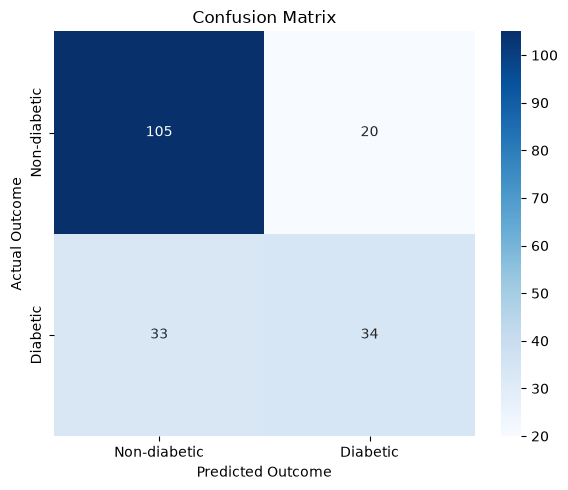

In [19]:
# ==========================================
# 11. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-diabetic", "Diabetic"],
    yticklabels=["Non-diabetic", "Diabetic"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.tight_layout()
plt.show()

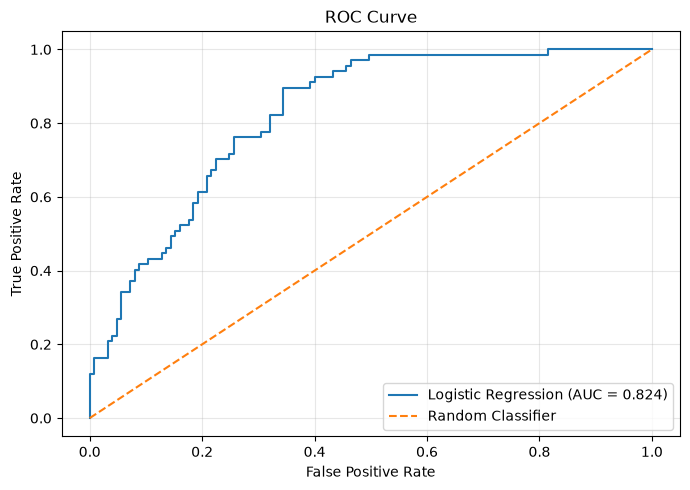

In [20]:
# ==========================================
# 12. ROC CURVE
# ==========================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
# ==========================================
# 13. COEFFICIENT INTERPRETATION
# ==========================================

classifier = log_model.named_steps["classifier"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": classifier.coef_[0]
})

coefficients["Odds Ratio"] = np.exp(
    coefficients["Coefficient"]
)

coefficients["Absolute Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print("Logistic Regression Coefficients:")
print(coefficients.to_string(index=False))

Logistic Regression Coefficients:
                 Feature  Coefficient  Odds Ratio  Absolute Coefficient
                 Glucose     1.161356    3.194262              1.161356
                     BMI     0.723911    2.062485              0.723911
             Pregnancies     0.440424    1.553366              0.440424
DiabetesPedigreeFunction     0.212235    1.236439              0.212235
                     Age     0.126012    1.134296              0.126012
           SkinThickness    -0.058248    0.943416              0.058248
           BloodPressure    -0.057382    0.944233              0.057382
                 Insulin    -0.030690    0.969776              0.030690


In [22]:
# ==========================================
# 14. CROSS-VALIDATION
# ==========================================

cv_scores = cross_val_score(
    log_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Five-fold cross-validation accuracy scores:")
print(cv_scores)

print("\nMean cross-validation accuracy:")
print(round(cv_scores.mean(), 4))

print("\nStandard deviation:")
print(round(cv_scores.std(), 4))

Five-fold cross-validation accuracy scores:
[0.75       0.75652174 0.79130435 0.8        0.8       ]

Mean cross-validation accuracy:
0.7796

Standard deviation:
0.0218


In [23]:
# ==========================================
# 15. SAVE THE TRAINED MODEL
# ==========================================

model_path = "logistic_model.pkl"

with open(model_path, "wb") as file:
    pickle.dump(log_model, file)

print("Model saved successfully!")
print("Saved path:", os.path.abspath(model_path))

Model saved successfully!
Saved path: C:\Users\adish\python_practice\Data Science\Assignments\Assignment 8\logistic_model.pkl


In [24]:
import pickle
import os

with open("logistic_model.pkl", "wb") as file:
    pickle.dump(log_model, file)

print("Model saved at:", os.path.abspath("logistic_model.pkl"))

Model saved at: C:\Users\adish\python_practice\Data Science\Assignments\Assignment 8\logistic_model.pkl
